# Nanoguide with an AmBe source: tracks and their directions

**Tsviki Y. Hirsh** · 2 November 2026

A nanoguide (EJ-200-type scintillating fibres in PMMA, 10 mm × 10 mm × 100 mm, fibres
along the length) is viewed end-on through the LumaCam microscope, with an AmBe source
50 mm from its axis at eight azimuths. G4LumaCam (branch `nanoguide`) moves every
scintillation photon trapped by the fibres to the end face at its birth position. This
notebook shows the setup, what single events look like, how a track's direction is
measured, and the track directions for every source position. The full analysis
(rates, coincidences, EMPIR) is in `ambe_azimuth_scan.ipynb`, whose simulations this
notebook reads from `archive/`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

REPO = Path.cwd().resolve().parents[1]          # this notebook lives in <G4LumaCam>/notebooks/nanoguide
sys.path.insert(0, str(REPO / "src"))
import lumacam
from lumacam.nanoguide import MICROSCOPE_ZFINE

ARCHIVE = Path("archive")                       # simulations of ambe_azimuth_scan.ipynb
AZIMUTHS = [0, 45, 90, 135, 180, 225, 270, 315]
MIN_PHOTONS = 20                                # visible track: guided photons on the end face
PIXEL_MM = 10.0 / 256                           # microscope pixel on the end face
FNUMBER = 8.0

INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLORS = {"n, first interaction": "#2a78d6", "n, after a scatter": "#eb6834", "γ": "#eda100"}
DETECTED = "#eb6834"
BLUES = LinearSegmentedColormap.from_list("blues", [SURFACE, "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#c3c2b7",
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "font.size": 9.5,
})

def clusters(particle, az):
    # visible, prompt light clusters of one run (see ambe_azimuth_scan.ipynb, section 2)
    c = pd.read_csv(ARCHIVE / f"{particle}_az{az:03d}" / "clusters_merge1.0_v2.csv.gz")
    return c[(c.n_photons >= MIN_PHOTONS) & (c.t < 100)].assign(particle=particle, azimuth=az)

_files = {}
def photons_of(particle, az, nid):
    # all photons of one event on the end face (SimPhotons files hold consecutive neutron_id ranges)
    d = ARCHIVE / f"{particle}_az{az:03d}" / "SimPhotons"
    if d not in _files:
        files = sorted(d.glob("sim_data_*.csv"), key=lambda f: int(f.stem.split("_")[-1]))
        files = [f for f in files if f.stat().st_size > 300]
        _files[d] = (files, np.array([pd.read_csv(f, usecols=["neutron_id"], nrows=1).neutron_id[0] for f in files]))
    files, first = _files[d]
    df = pd.read_csv(files[np.searchsorted(first, nid, side="right") - 1])
    return df[df.neutron_id == nid]

def detected_of(particle, az):
    # photons the camera records: through the microscope, 24 % detection efficiency
    d = pd.read_csv(ARCHIVE / f"{particle}_az{az:03d}" / f"detected_f{FNUMBER}_qe0.241.csv.gz")
    return d.assign(x=(d.pixel_x - 128.5) * PIXEL_MM, y=(d.pixel_y - 128.5) * PIXEL_MM)

def scale_bar(ax, x0, y0, length, label, color=INK):
    # thin scale bar with end caps
    ax.plot([x0, x0 + length], [y0, y0], color=color, lw=1.2, solid_capstyle="butt")
    for x in (x0, x0 + length):
        ax.plot([x, x], [y0 - length * 0.06, y0 + length * 0.06], color=color, lw=1.2)
    ax.text(x0 + length / 2, y0 + length * 0.1, label, ha="center", va="bottom", fontsize=8.5, color=color)

## The setup

The Geant4 geometry (ray-traced from `figures/nanoguide_geant4_raytrace.mac`): the guide
with its viewed end face in red. The source sits beside the guide, perpendicular to its
axis; its azimuth is measured in the end-face plane.

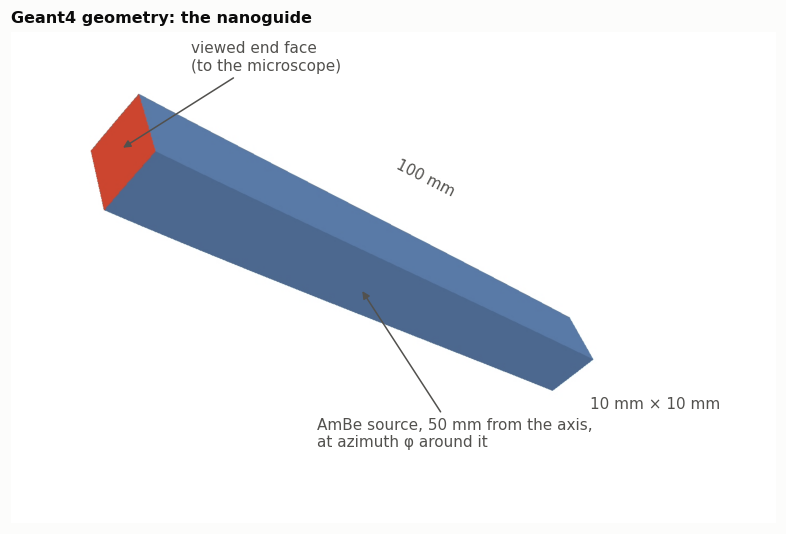

In [2]:
img = plt.imread("figures/nanoguide_geant4.jpg")
fig, ax = plt.subplots(figsize=(9, 5.8))
ax.imshow(img); ax.set_axis_off()
kw = dict(color=INK2, fontsize=10, arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1))
ax.annotate("viewed end face\n(to the microscope)", xy=(200, 215), xytext=(330, 70), **kw)
ax.annotate("AmBe source, 50 mm from the axis,\nat azimuth φ around it", xy=(640, 470), xytext=(560, 760), **kw)
ax.text(700, 300, "100 mm", rotation=-27, color=INK2, fontsize=10)
ax.text(1060, 690, "10 mm × 10 mm", color=INK2, fontsize=10)
ax.set_title("Geant4 geometry: the nanoguide", loc="left")
plt.show()

The microscope as traced with rayoptics: a reversed 50 mm lens in front of an
80–200 mm zoom lens (patent prescriptions), at f/8, focused on the end face (left) and
imaging it onto the camera (right).

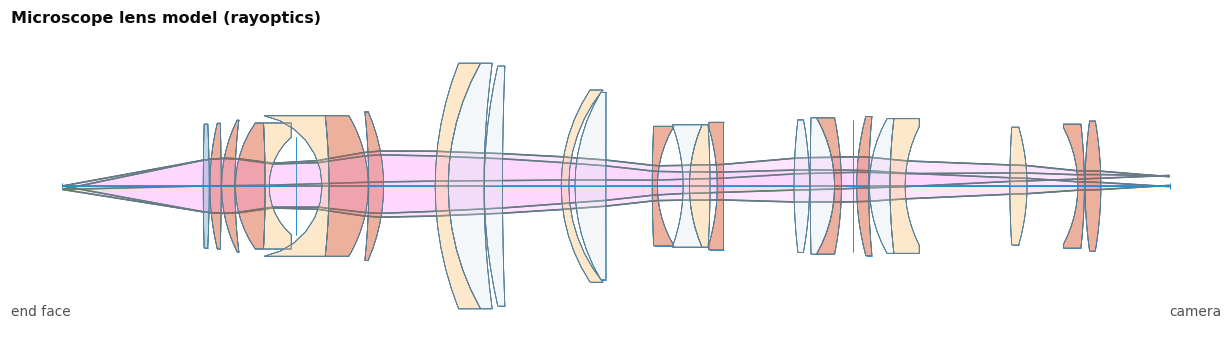

In [3]:
import logging
logging.getLogger("matplotlib.axes._base").setLevel(logging.ERROR)   # rayoptics' fixed-aspect notices
lens = lumacam.Lens(data=pd.DataFrame(), kind="microscope", zfine=MICROSCOPE_ZFINE, fnumber=FNUMBER, verbosity=0)
with plt.rc_context():                     # rayoptics restyles matplotlib; keep it to this figure
    lens.plot(lens.refocus(zfine=MICROSCOPE_ZFINE, fnumber=FNUMBER), kind="layout", figsize=(11, 2.8), dpi=110)
    ax = plt.gcf().axes[0]
    ax.set_title("Microscope lens model (rayoptics)", loc="left", fontsize=10.5, fontweight="bold", color=INK)
    ax.text(0.0, 0.08, "end face", transform=ax.transAxes, color=INK2, fontsize=9)
    ax.text(1.0, 0.08, "camera", transform=ax.transAxes, color=INK2, fontsize=9, ha="right")
    plt.show()

## What events look like

Four simulated events with the source at 0° (on the +x side). Blue: every photon the
fibres carry to the end face, binned in microscope pixels (39 µm). Orange circles: the
photons the camera records (about 6 % of them enter the f/8 lens, 24 % of those are
detected). Recoil protons stop within a fraction of a millimetre; a gamma's Compton
electron runs for millimetres, so a few detected photons on one electron track can lie
9 mm apart.

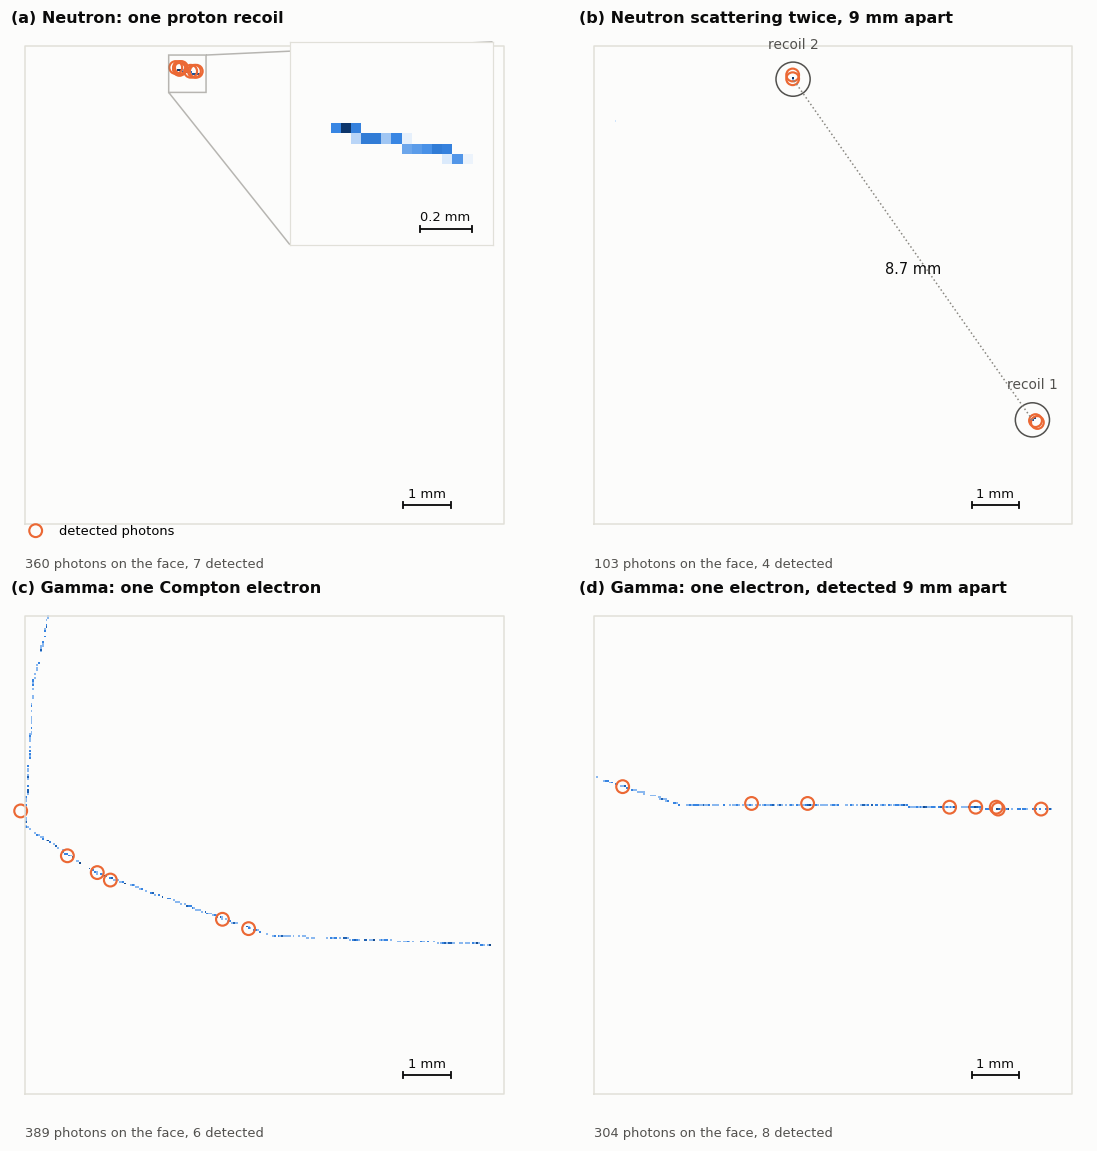

In [4]:
AZ = 0
cn, cg = clusters("neutron", AZ), clusters("gamma", AZ)
dn, dg = detected_of("neutron", AZ), detected_of("gamma", AZ)
n_cl_n, n_cl_g = cn.groupby("neutron_id").size(), cg.groupby("neutron_id").size()

# (a) one proton recoil: a single emitting particle, many photons, the longest projected track
f0 = sorted((ARCHIVE / f"neutron_az{AZ:03d}" / "SimPhotons").glob("sim_data_*.csv"))[0]
ph0 = pd.read_csv(f0)
ev = ph0.groupby("neutron_id").agg(parents=("parent_id", "nunique"), kind=("parentName", "first"),
                                   n=("x", "size"), ext=("x", lambda x: np.ptp(x)))
ev["ext"] = np.maximum(ev.ext, ph0.groupby("neutron_id").y.agg(np.ptp))
a = ev[(ev.parents == 1) & (ev.kind == "proton") & (ev.n >= 150)].ext.idxmax()

# (b) a neutron scattering twice, ~9 mm apart, with detected photons from both recoils
two = cn[cn.neutron_id.map(n_cl_n) == 2]
sep = two.groupby("neutron_id")[["x", "y"]].apply(lambda g: np.hypot(*np.diff(g.to_numpy(), axis=0)[0]))
seen = dn.groupby("neutron_id").n_int.nunique()      # recoils with a detected photon
dim = two.groupby("neutron_id").n_photons.min()       # the fainter of the two recoils
far = sep[(sep > 8) & (sep < 10)].index
b = max(far, key=lambda i: (seen.get(i, 0), dim[i]))

# (c) one long Compton electron; (d) one gamma interaction whose detected photons span ~9 mm
c = cg[cg.neutron_id.map(n_cl_g) == 1].sort_values("rms").neutron_id.iloc[-1]
span = dg.groupby("neutron_id")[["x", "y"]].apply(lambda g: np.ptp(g.to_numpy(), axis=0).max())
nd = dg.groupby("neutron_id").size()
d = next(i for i in span[(span > 8.5) & (span < 9.5)].index if nd[i] >= 5 and n_cl_g.get(i, 0) == 1 and i != c)

examples = [("neutron", a, dn, "(a) Neutron: one proton recoil"),
            ("neutron", b, dn, "(b) Neutron scattering twice, 9 mm apart"),
            ("gamma", c, dg, "(c) Gamma: one Compton electron"),
            ("gamma", d, dg, "(d) Gamma: one electron, detected 9 mm apart")]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 10.5))
edges = np.linspace(-5, 5, 257)
for ax, (p, nid, det, title) in zip(axes.flat, examples):
    ph = photons_of(p, AZ, nid)
    h = np.histogram2d(ph.x, ph.y, [edges, edges])[0]
    ax.imshow(np.where(h > 0, np.log1p(h), np.nan).T, origin="lower", extent=[-5, 5, -5, 5], cmap=BLUES,
              vmin=0, interpolation="nearest")
    dd = det[det.neutron_id == nid]
    ax.scatter(dd.x, dd.y, s=70, facecolors="none", edgecolors=DETECTED, linewidths=1.4,
               label="detected photons")
    ax.plot([-5, 5, 5, -5, -5], [-5, -5, 5, 5, -5], color=GRID, lw=1)   # end face of the guide
    ax.set_xlim(-5.3, 5.3); ax.set_ylim(-5.3, 5.3); ax.set_axis_off()
    ax.set_title(title, loc="left")
    ax.text(-5, -5.9, f"{len(ph)} photons on the face, {len(dd)} detected", color=INK2, fontsize=8.5)
    scale_bar(ax, 2.9, -4.6, 1.0, "1 mm")
    spots = cn[cn.neutron_id == nid][["x", "y"]].to_numpy() if p == "neutron" else []
    if len(spots) == 2:   # mark the two recoils and their separation
        (x1, y1), (x2, y2) = spots
        ax.plot([x1, x2], [y1, y2], color=MUTED, lw=1, ls=":")
        for k, (cx, cy) in enumerate(spots, 1):
            ax.scatter(cx, cy, s=500, facecolors="none", edgecolors=INK2, linewidths=1)
            ax.text(cx, cy + 0.65, f"recoil {k}", ha="center", color=INK2, fontsize=9)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 - 0.5, f"{np.hypot(x2 - x1, y2 - y1):.1f} mm", ha="center",
                color=INK, fontsize=9.5)
    if len(spots) == 1:   # zoom on the recoil
        for cx, cy in spots:
            ins = ax.inset_axes([0.55, 0.58, 0.4, 0.4])
            w = 0.4
            ex, ey = cx + np.arange(-w, w + 1e-9, PIXEL_MM), cy + np.arange(-w, w + 1e-9, PIXEL_MM)
            hz = np.histogram2d(ph.x, ph.y, [ex, ey])[0]
            ins.imshow(np.where(hz > 0, hz, np.nan).T, origin="lower", extent=[ex[0], ex[-1], ey[0], ey[-1]],
                       cmap=BLUES, vmin=0, interpolation="nearest")
            ins.set_xticks([]); ins.set_yticks([])
            for s in ins.spines.values():
                s.set_color(GRID)
            scale_bar(ins, cx + w - 0.3, cy - w + 0.06, 0.2, "0.2 mm")
            ax.indicate_inset_zoom(ins, edgecolor=MUTED, alpha=0.6)
axes.flat[0].legend(loc="lower left", bbox_to_anchor=(0, -0.02), fontsize=8.5)
fig.tight_layout()
plt.show()

## How the track angle is measured

A track's direction runs from where its charged particle starts (the recoil vertex, from
Geant4) to the centroid of its light, which leans towards the end of the track where
the particle deposits the most energy. The track angle θ is that direction in the
end-face plane, measured from +x like the source azimuth φ. A recoil proton carries the
neutron's momentum forward, so θ points away from the source: θ ≈ φ + 180°. (In data,
without the vertex, the same direction comes from the track's axis and its brighter end.)

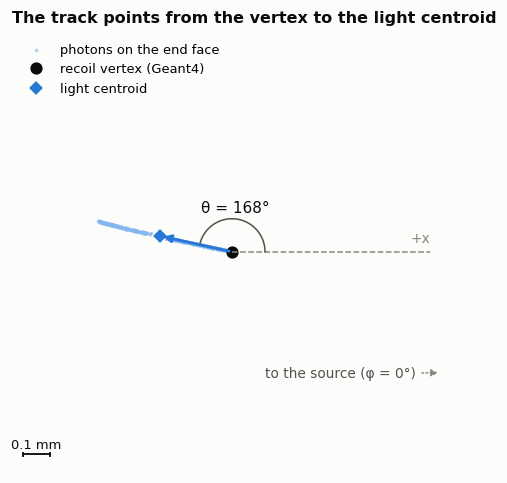

In [5]:
ph = photons_of("neutron", AZ, a)
x0, y0 = ph.px.iloc[0], ph.py.iloc[0]          # recoil vertex
cx, cy = ph.x.mean(), ph.y.mean()              # light centroid
theta = np.degrees(np.arctan2(cy - y0, cx - x0)) % 360
L = np.hypot(cx - x0, cy - y0)

fig, ax = plt.subplots(figsize=(6.5, 5.2))
w = max(3 * L, 0.25)
ax.scatter(ph.x - x0, ph.y - y0, s=6, color="#86b6ef", alpha=0.6, lw=0, label="photons on the end face")
ax.plot(0, 0, "o", color=INK, ms=7, label="recoil vertex (Geant4)")
ax.plot(cx - x0, cy - y0, "D", color=COLORS["n, first interaction"], ms=7, mec=SURFACE, label="light centroid")
ax.annotate("", xy=(cx - x0, cy - y0), xytext=(0, 0),
            arrowprops=dict(arrowstyle="-|>", color=COLORS["n, first interaction"], lw=2))
ax.plot([0, w * 0.9], [0, 0], color=MUTED, lw=1, ls="--")                       # +x reference
arc = np.radians(np.linspace(0, theta if theta <= 180 else theta - 360, 60))
ax.plot(0.45 * L * np.cos(arc), 0.45 * L * np.sin(arc), color=INK2, lw=1)
mid = arc[len(arc) // 2]
ax.text(0.6 * L * np.cos(mid), 0.6 * L * np.sin(mid), f"θ = {theta:.0f}°", color=INK, fontsize=10,
        ha="center", va="center")
ax.annotate("to the source (φ = 0°)", xy=(w * 0.95, -w * 0.55), xytext=(w * 0.15, -w * 0.55),
            color=INK2, fontsize=9, va="center", arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1, ls=":"))
ax.text(w * 0.9, w * 0.03, "+x", color=MUTED, fontsize=9, ha="right", va="bottom")
ax.set_xlim(-w, w); ax.set_ylim(-w, w); ax.set_aspect("equal"); ax.set_axis_off()
scale_bar(ax, -w * 0.95, -w * 0.92, 0.1, "0.1 mm")
ax.set_title("The track points from the vertex to the light centroid", loc="left")
ax.legend(loc="upper left", fontsize=8.5)
plt.show()

## Track angles for the eight source positions

For every visible track (at least 20 photons on the end face, at least 50 µm from vertex
to centroid), the distribution of θ for each component, each normalised to its own total:
neutrons whose light comes from their first interaction in the guide, neutrons whose light
comes after a scatter (on carbon or hydrogen first), and gamma electrons. The grey line
points to the source.

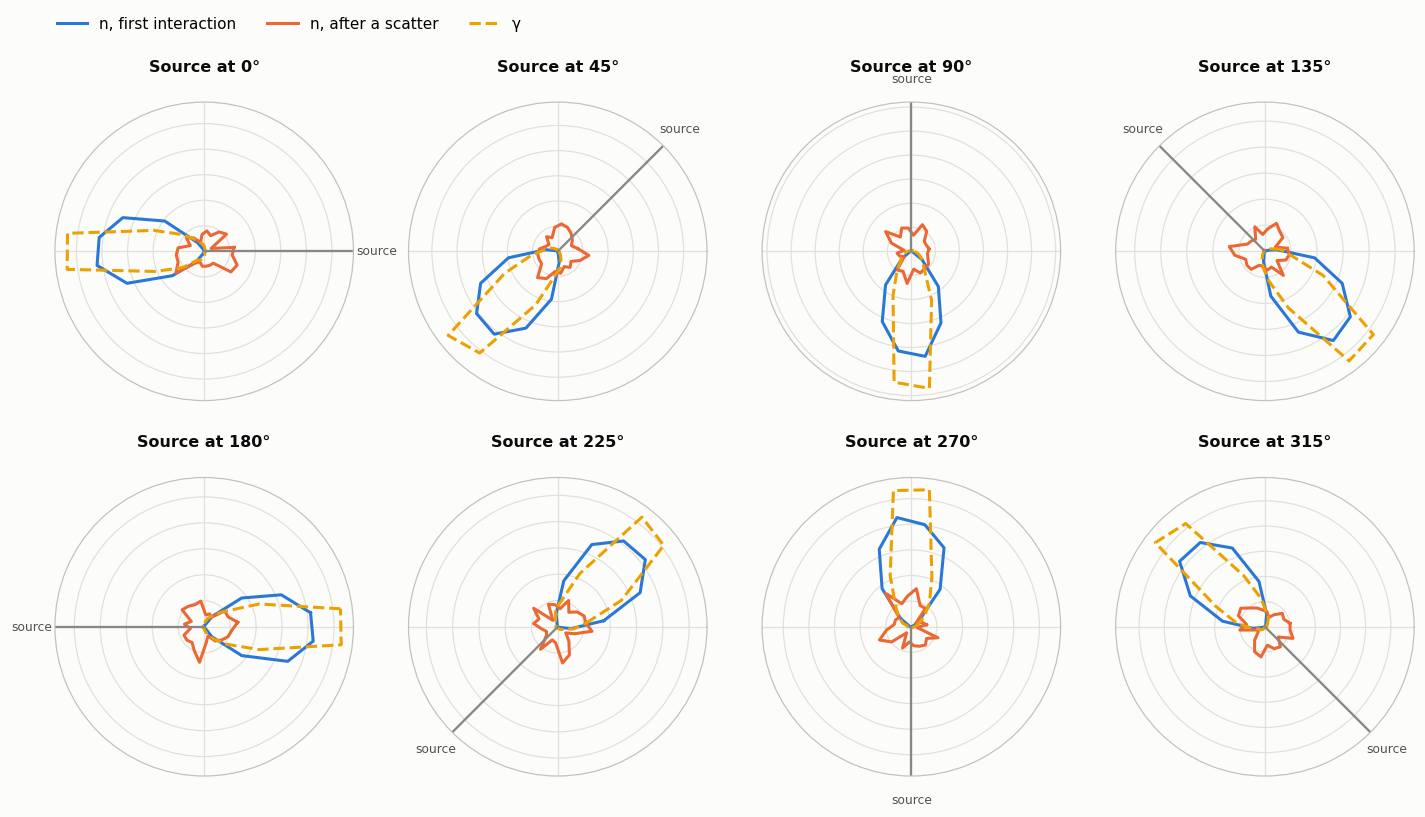

,tracks,pointing_away
component,,
"n, first interaction",21409,98.9 %
"n, after a scatter",2172,47.7 %
γ,22384,96.8 %


In [6]:
tracks = pd.concat([clusters(p, az) for az in AZIMUTHS for p in ("neutron", "gamma")], ignore_index=True)
tracks["length"] = np.hypot(tracks.x - tracks.px, tracks.y - tracks.py)
tracks = tracks[tracks.length > 0.05]
tracks["theta"] = np.degrees(np.arctan2(tracks.y - tracks.py, tracks.x - tracks.px)) % 360
tracks["component"] = np.select([tracks.particle == "gamma", tracks.n_int == 1],
                                ["γ", "n, first interaction"], default="n, after a scatter")

edges = np.arange(0, 361, 15)
centres = np.radians(np.r_[edges[:-1] + 7.5, edges[0] + 7.5])   # closed curve
fig, axes = plt.subplots(2, 4, figsize=(13, 7.2), subplot_kw={"projection": "polar"})
for ax, az in zip(axes.flat, AZIMUTHS):
    top = 0
    for comp, color in COLORS.items():
        th = tracks.theta[(tracks.azimuth == az) & (tracks.component == comp)]
        h = np.histogram(th, edges)[0] / len(th)
        ax.plot(centres, np.r_[h, h[0]], color=color, lw=2, ls="--" if comp == "γ" else "-",
                label=f"{comp}")
        top = max(top, h.max())
    ax.set_ylim(0, top * 1.08)
    ax.plot([np.radians(az)] * 2, [0, top * 1.08], color=MUTED, lw=1.5)
    ax.text(np.radians(az), top * 1.25, "source", color=INK2, ha="center", va="center", fontsize=8)
    ax.set_title(f"Source at {az}°", pad=20)
    ax.set_yticklabels([]); ax.set_xticks(np.radians(range(0, 360, 90))); ax.set_xticklabels([])
    ax.grid(color=GRID)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper left", bbox_to_anchor=(0.03, 1.04), fontsize=10)
fig.tight_layout()
plt.show()

summary = (tracks.assign(away=np.cos(np.radians(tracks.theta - tracks.azimuth - 180)))
                 .groupby("component")
                 .agg(tracks=("theta", "size"), pointing_away=("away", lambda c: (c > 0).mean())))
summary["pointing_away"] = (100 * summary.pointing_away).round(1).astype(str) + " %"
summary.loc[list(COLORS)]